# PSD PREDICTION ANALYSIS

In [1]:
import matplotlib.pyplot as plt  # type: ignore
import numpy as np  # type: ignore
import os
import pandas as pd  # type: ignore
from typing import Optional, cast, List, Union

import src.constants as cn
from src.psd_prediction_file_iterator import PSDPredictionFileIterator
from src.psd_prediction_analyzer import PSDPredictionAnalyzer
from src.nl_curve import NLCurve
from src.piecewise_system_discovery import PiecewiseSystemDiscovery
from src.biomodels_iterator import BiomodelsIterator
from src.timecourse_iterator import TimecourseIterator
from src.model import Model

# Data analysis

In [2]:
def fileFilter(dct) -> bool:
    if not cn.COL_MAX_FRACTIONAL_REDUCTION in dct:
        return False
    if dct[cn.COL_MAX_FRACTIONAL_REDUCTION] !=  1e-5:
        pass
        #return False
    if dct[cn.COL_REPEAT] > 1:
        pass
        #return False
    return True



In [3]:
def dataframeFilter(df, dct) -> pd.DataFrame:
    new_df = df.copy()
    return new_df[ new_df [cn.COL_AGGREGATION_TYPE] == "model"]

In [4]:
df = PSDPredictionFileIterator.query(file_filter=fileFilter, data_frame_filter=dataframeFilter,
        is_guard_filename=True)
#df = df [ df[cn.COL_SYSTEM_ID] == "BIOMD0000000297"]
df = df.reset_index()
df[[cn.COL_SYSTEM_ID, cn.COL_P50, cn.COL_AUC]]

,system_id,p50,auc
0,BIOMD0000000005,0.950792,0.972043
1,BIOMD0000000010,0.864240,0.997727
2,BIOMD0000000042,0.969149,0.996254
3,BIOMD0000000234,0.386742,0.468664
4,BIOMD0000000278,1.000000,0.999800
...,...,...,...
8592,BIOMD0000001056,0.887416,0.879896
8593,BIOMD0000001057,0.499990,0.597396
8594,BIOMD0000001058,0.999633,0.999762
8595,BIOMD0000001059,0.997745,0.924847


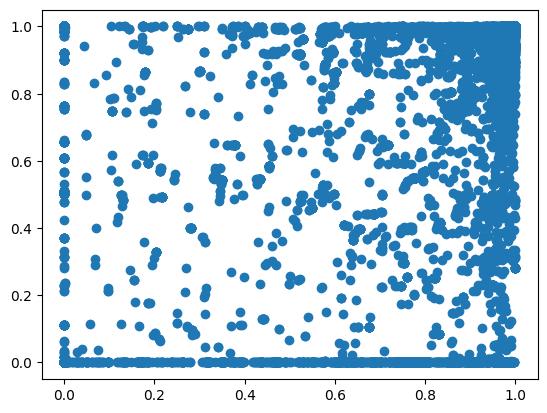

In [5]:
plt.scatter(df[cn.COL_AUC].values, df[cn.COL_P50].values)

In [6]:
#df.loc[df.groupby('A')['B'].idxmin(), ['A', 'B', 'C']]
df1 = df[df[cn.COL_P50] > 0.8]
dff = df1.loc[df1.groupby(cn.COL_SYSTEM_ID)[cn.COL_AUC].idxmin(),[cn.COL_SYSTEM_ID,
            cn.COL_NUM_CHANGEPOINT, cn.COL_AUC, cn.COL_P50, cn.COL_FILENAME, cn.COL_CHANGEPOINTS]]
dff

,system_id,num_changepoint,auc,p50,filename,changepoints
1938,BIOMD0000000005,121,0.895795,0.841488,piecewise_predictions__numpoint_100000__thresh...,"[20, 40, 60, 80, 9738, 9758, 9778, 9798, 9818,..."
1525,BIOMD0000000010,1741,0.995949,0.807855,piecewise_predictions__numpoint_100000__thresh...,"[20, 40, 60, 80, 100, 120, 140, 160, 180, 200,..."
267,BIOMD0000000042,314,0.984928,0.834115,piecewise_predictions__numpoint_100000__thresh...,"[20, 160, 180, 200, 220, 240, 700, 720, 1240, ..."
688,BIOMD0000000234,78,0.930334,0.895649,piecewise_predictions__numpoint_100000__thresh...,"[1660, 1680, 2400, 2420, 2500, 2519, 4999, 501..."
269,BIOMD0000000278,0,0.000000,0.999934,piecewise_predictions__numpoint_100000__thresh...,[]
...,...,...,...,...,...,...
7755,BIOMD0000001055,1769,0.945224,0.994552,piecewise_predictions__numpoint_100000__thresh...,"[20, 40, 60, 80, 100, 120, 140, 160, 180, 200,..."
1933,BIOMD0000001056,254,0.666947,0.871495,piecewise_predictions__numpoint_100000__thresh...,"[20, 40, 60, 80, 100, 120, 140, 160, 180, 200,..."
3601,BIOMD0000001058,687,0.971053,0.944739,piecewise_predictions__numpoint_100000__thresh...,"[20, 40, 60, 80, 100, 120, 140, 160, 180, 200,..."
3186,BIOMD0000001059,1392,0.912866,0.847472,piecewise_predictions__numpoint_100000__thresh...,"[20, 40, 60, 80, 100, 120, 140, 160, 180, 200,..."


# AUC and Model Accuracy

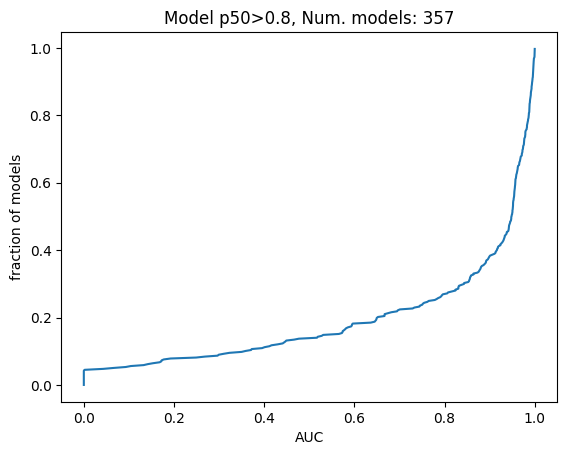

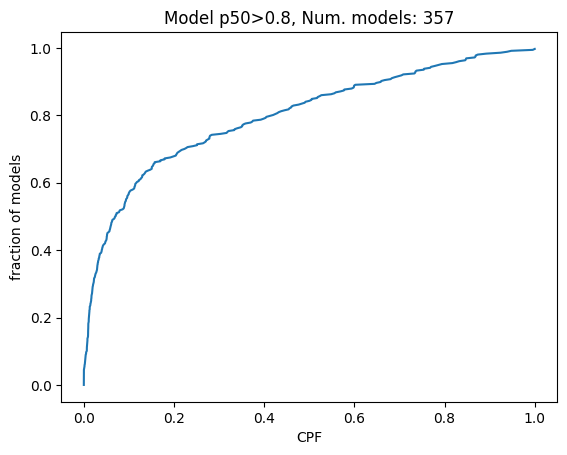

In [29]:
# Parameters
accuracy_threshold = 0.8
statistic = cn.COL_P50
#statistic = cn.COL_MIN

# Data construction
df = PSDPredictionFileIterator.query(file_filter=fileFilter, data_frame_filter=dataframeFilter,
        is_guard_filename=True)
df = df.reset_index()
df1 = df[df[statistic] > accuracy_threshold]
MODEL_DF = df1.loc[df1.groupby(cn.COL_SYSTEM_ID)[cn.COL_AUC].idxmin(),
    [cn.COL_SYSTEM_ID, cn.COL_NUM_CHANGEPOINT, cn.COL_AUC, cn.COL_P50, cn.COL_MAX, cn.COL_MIN, 
     cn.COL_FILENAME, cn.COL_CHANGEPOINTS]]
MODEL_DF["CPF"] = MODEL_DF[cn.COL_NUM_CHANGEPOINT] / 5000  # Account for lower max values
num_model = len(MODEL_DF[cn.COL_SYSTEM_ID].unique())
fraction_model = np.array(range(num_model))/num_model

sorted_auc = np.sort(MODEL_DF[cn.COL_AUC].values)
plt.plot(sorted_auc, fraction_model)
title = f"Model {statistic}>{accuracy_threshold}, Num. models: {num_model}"
plt.title(title)
plt.xlabel("AUC")
plt.ylabel("fraction of models")
plt.figure()


sorted_auc = np.sort(MODEL_DF["CPF"].values)
plt.plot(sorted_auc, fraction_model)
title = f"Model {statistic}>{accuracy_threshold}, Num. models: {num_model}"
plt.title(title)
plt.xlabel("CPF")
_ = plt.ylabel("fraction of models")

AUC indicates that there are 3 types of models
* Those that are well approximated by a single linear system
* Those that require a modest to significant number of piecewise approximations
* Those that require a very dense series of piecewise approximations

# AUC vs. Changepoints

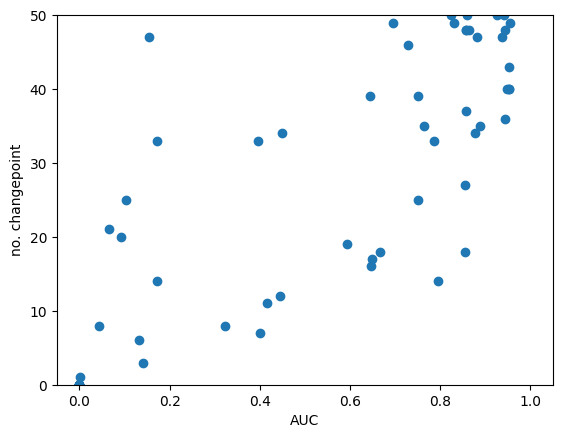

In [31]:
plt.scatter(MODEL_DF["auc"], MODEL_DF["num_changepoint"])
plt.ylim([0, 50])
plt.xlabel("AUC")
_ = plt.ylabel("no. changepoint")

There are 10 coincident points at (0, 0)

# Timecourse plots

In [23]:
MODEL_DF [ MODEL_DF[cn.COL_NUM_CHANGEPOINT] <= 10 ][[cn.COL_SYSTEM_ID, cn.COL_AUC, cn.COL_P50, cn.COL_NUM_CHANGEPOINT]]

,system_id,auc,p50,num_changepoint
269,BIOMD0000000278,0.000000,0.999934,0
344,BIOMD0000000677,0.000000,0.922101,0
389,BIOMD0000000736,0.000000,1.000000,0
396,BIOMD0000000745,0.000000,0.983569,0
449,BIOMD0000000799,0.000000,0.899953,0
1707,BIOMD0000000802,0.190297,0.999875,2
455,BIOMD0000000807,0.000000,1.000000,0
461,BIOMD0000000814,0.000000,0.989611,0
1314,BIOMD0000000830,0.184557,0.928872,2
522,BIOMD0000000885,0.000000,1.000000,0


# Illustration of the different model types

In [8]:
t_iter = TimecourseIterator(first_model_num=278, last_model_num=278)
item = list(t_iter)[0]
ser = MODEL_DF [MODEL_DF[cn.COL_SYSTEM_ID] == item.model_name].iloc[0]
ser

system_id                                            BIOMD0000000278
num_changepoint                                                    0
auc                                                              0.0
p50                                                         0.999934
max                                                         0.999978
min                                                         0.999918
filename           piecewise_predictions__numpoint_100000__thresh...
changepoints                                                      []
CPF                                                              0.0
Name: 269, dtype: object

In [32]:
mask = (MODEL_DF["auc"] > 0.3) & (MODEL_DF["auc"] < 0.6)
df = MODEL_DF[mask][[cn.COL_SYSTEM_ID, cn.COL_P50, cn.COL_NUM_CHANGEPOINT]]
MODEL_COLLECTION = [Model.getBiomodelNum(v) for v in df[cn.COL_SYSTEM_ID].values]
MODEL_DF[mask][[cn.COL_SYSTEM_ID, cn.COL_AUC, cn.COL_P50, cn.COL_NUM_CHANGEPOINT]]

,system_id,auc,p50,num_changepoint
5707,BIOMD0000000461,0.518575,0.954852,988
3646,BIOMD0000000571,0.581378,0.999305,77
1172,BIOMD0000000665,0.596228,0.862541,354
343,BIOMD0000000676,0.416132,0.854459,11
1603,BIOMD0000000679,0.448902,0.885868,34
2851,BIOMD0000000680,0.517067,0.917207,165
2443,BIOMD0000000690,0.565543,0.953030,765
7869,BIOMD0000000715,0.310230,0.922616,754
401,BIOMD0000000750,0.358733,0.917927,91
2497,BIOMD0000000760,0.530714,0.885460,52


Model 671 gets different accuracy than recorded.

In [27]:
def run(model_collection):
    t_iter = TimecourseIterator(model_num_collection=model_collection)
    for item in t_iter:
        df = item.timecourse.timecourse_df
        ser = MODEL_DF [MODEL_DF[cn.COL_SYSTEM_ID] == item.model_name].iloc[0]
        psd = PiecewiseSystemDiscovery(df, 
                changepoints=ser.changepoints,
                is_changepoint_removal=False,
                model_name=item.model_name)
        psd.fit()
        result = psd.plotPiecewise(legend=False, num_true_point=60, is_nochangepoint_plot=False)
        _ = plt.figure()

/Users/jlheller/home/Technical/repos/linearity_analysis/src/scaler.py:89: RuntimeWarning: overflow encountered in multiply
  denormalized_arr = normalized_arr * self._scale_arr
/Users/jlheller/home/Technical/repos/linearity_analysis/src/scaler.py:89: RuntimeWarning: overflow encountered in multiply
  denormalized_arr = normalized_arr * self._scale_arr
/Users/jlheller/home/Technical/repos/linearity_analysis/src/piecewise_system_discovery.py:822: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax_bot = plt.subplots(1, 1, figsize=figsize, sharex=True)


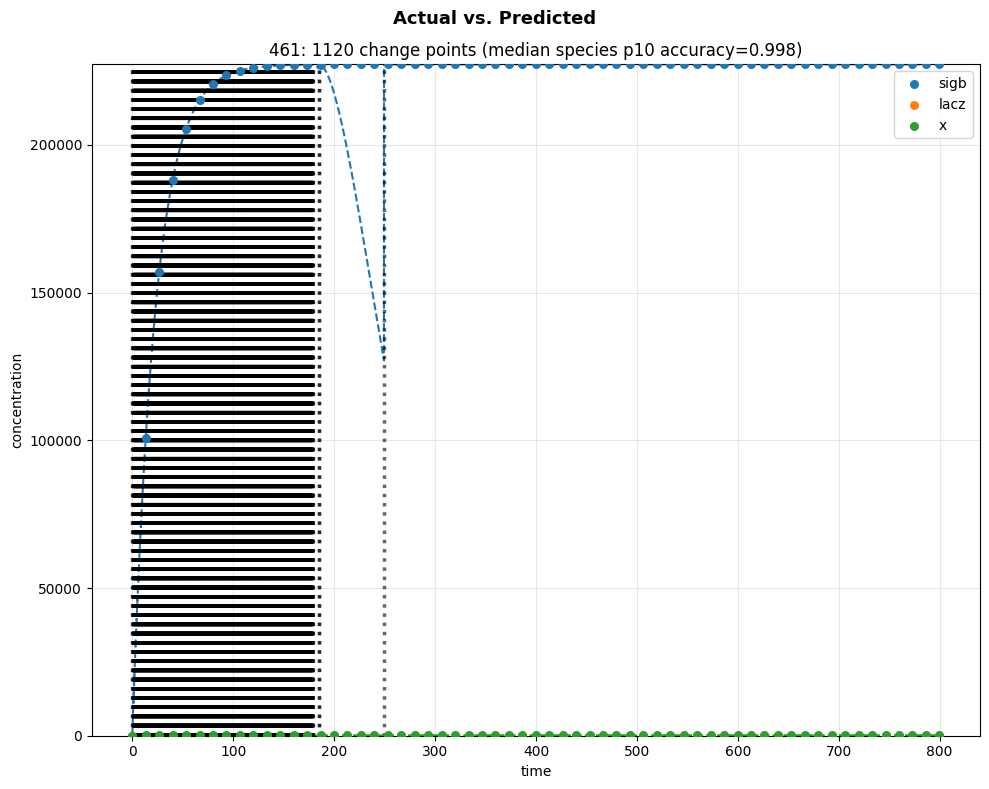

<Figure size 640x480 with 0 Axes>

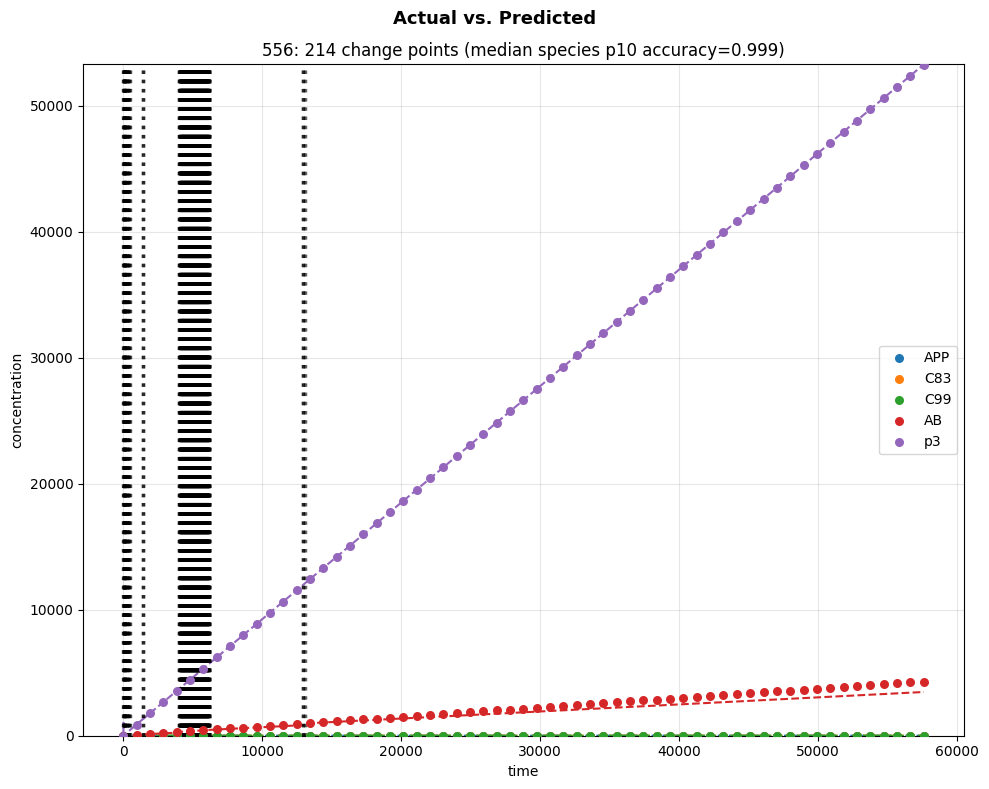

<Figure size 640x480 with 0 Axes>

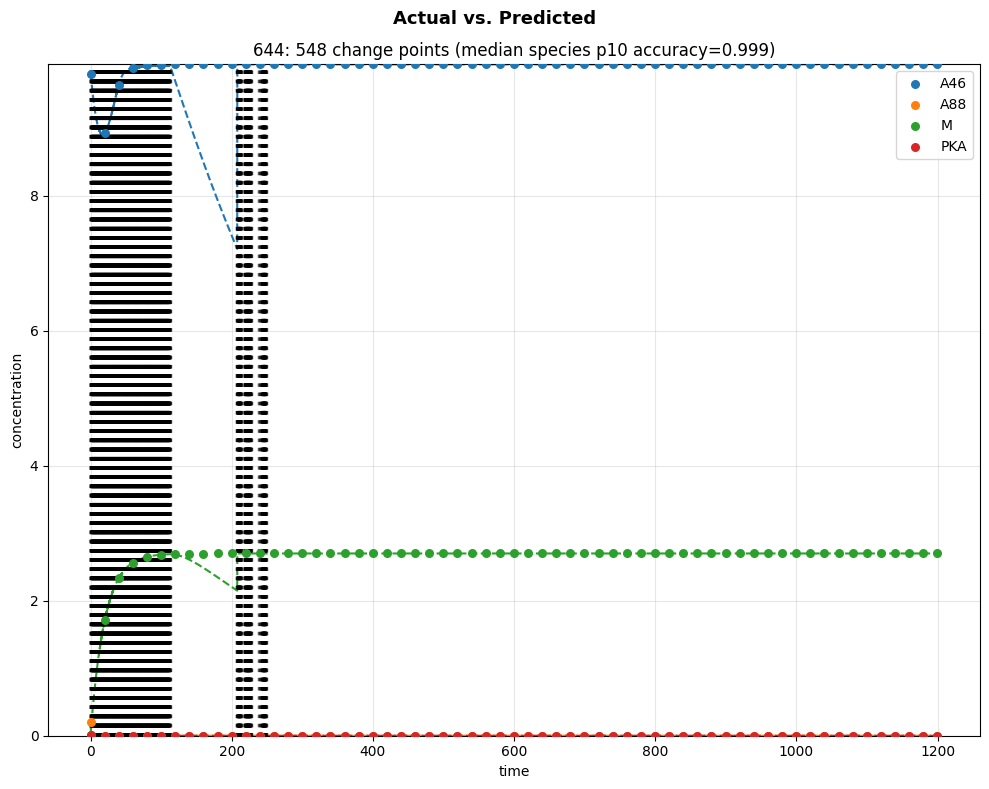

<Figure size 640x480 with 0 Axes>

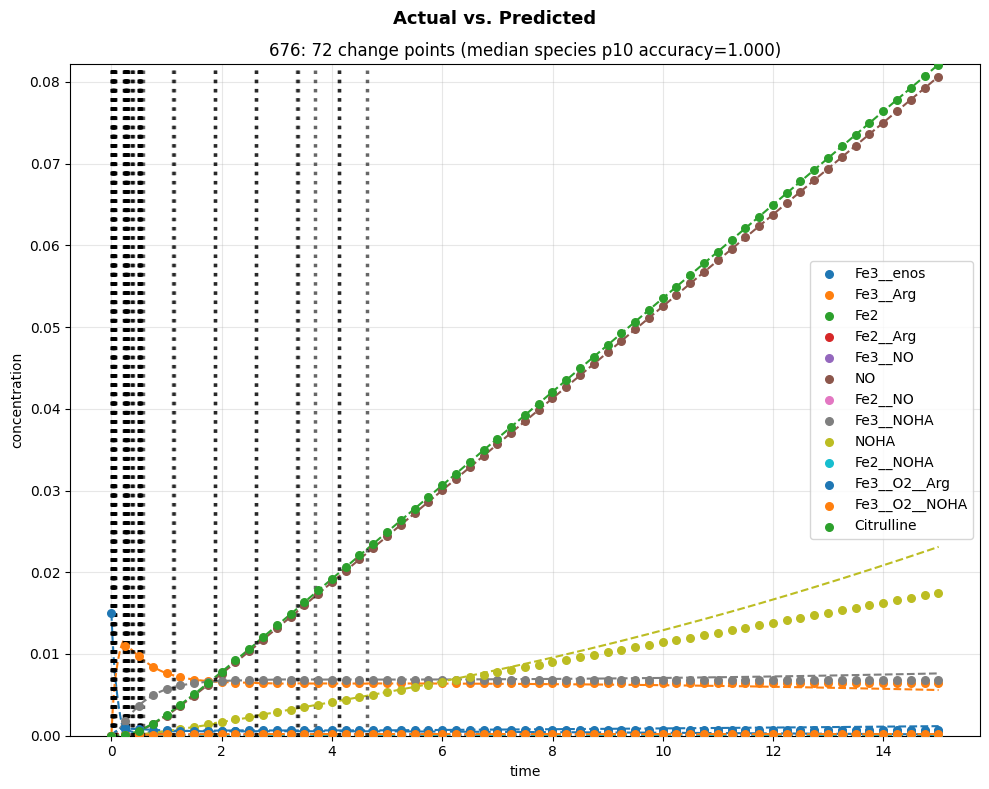

<Figure size 640x480 with 0 Axes>

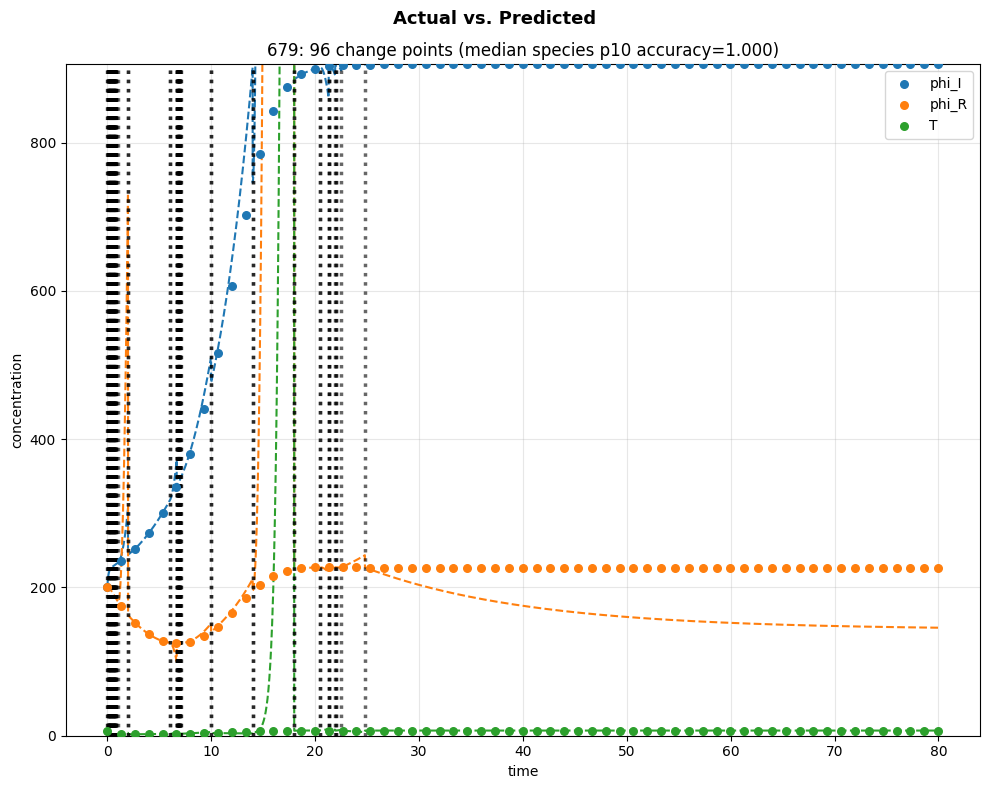

<Figure size 640x480 with 0 Axes>

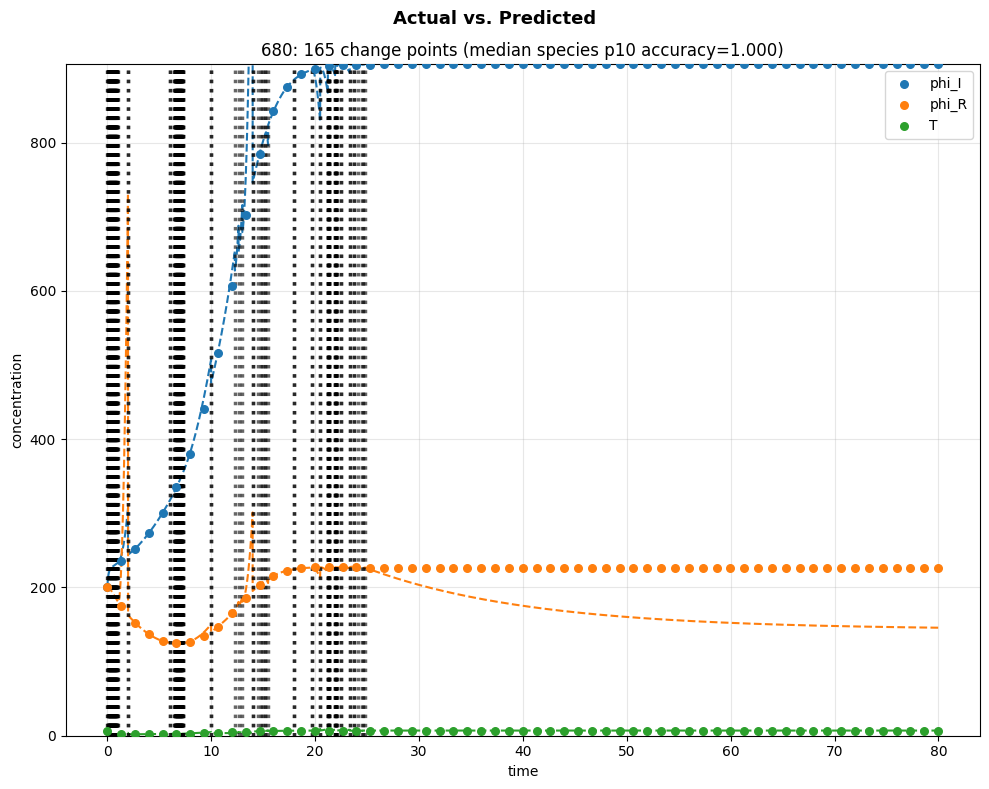

<Figure size 640x480 with 0 Axes>

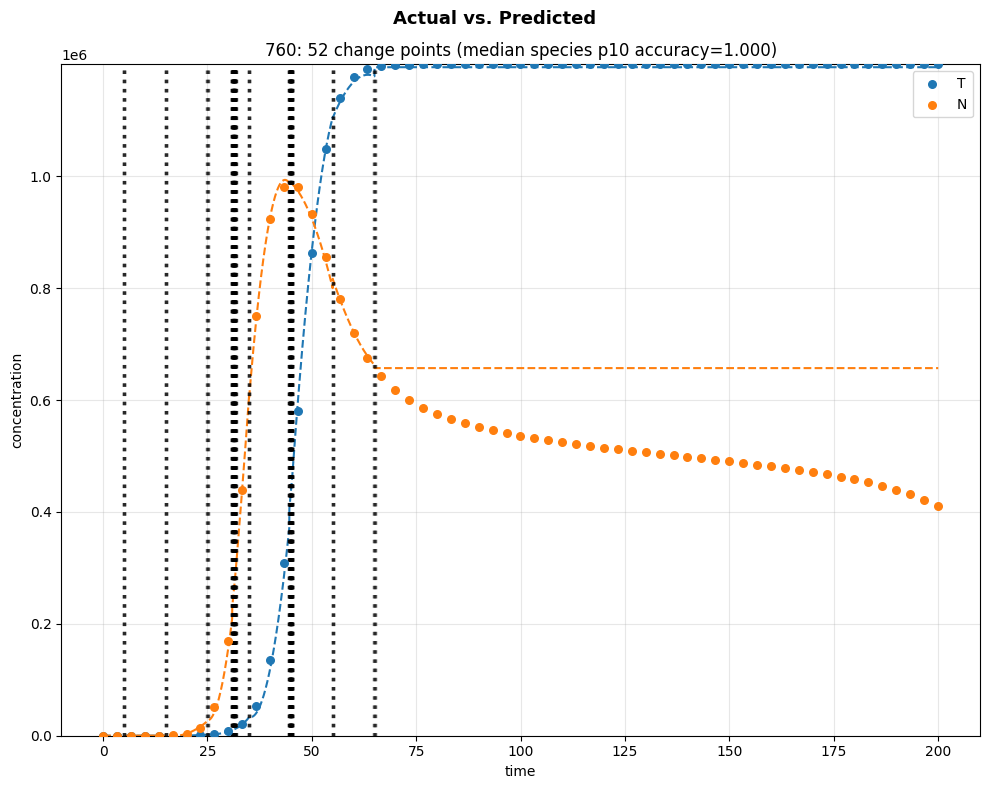

<Figure size 640x480 with 0 Axes>

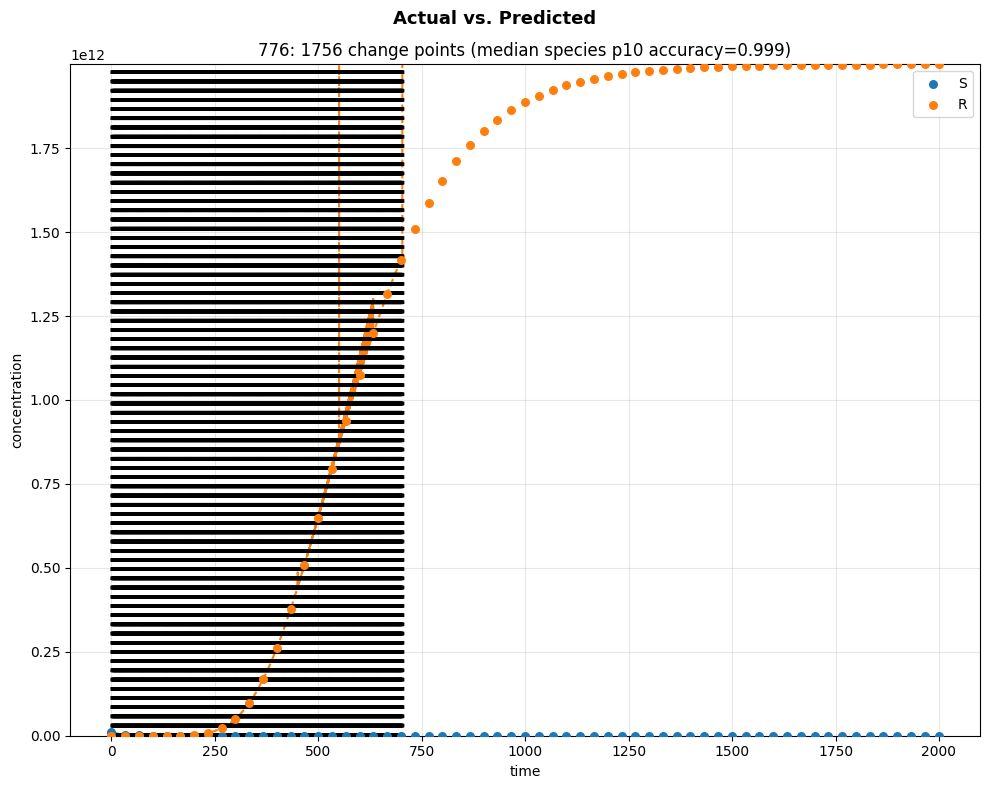

<Figure size 640x480 with 0 Axes>

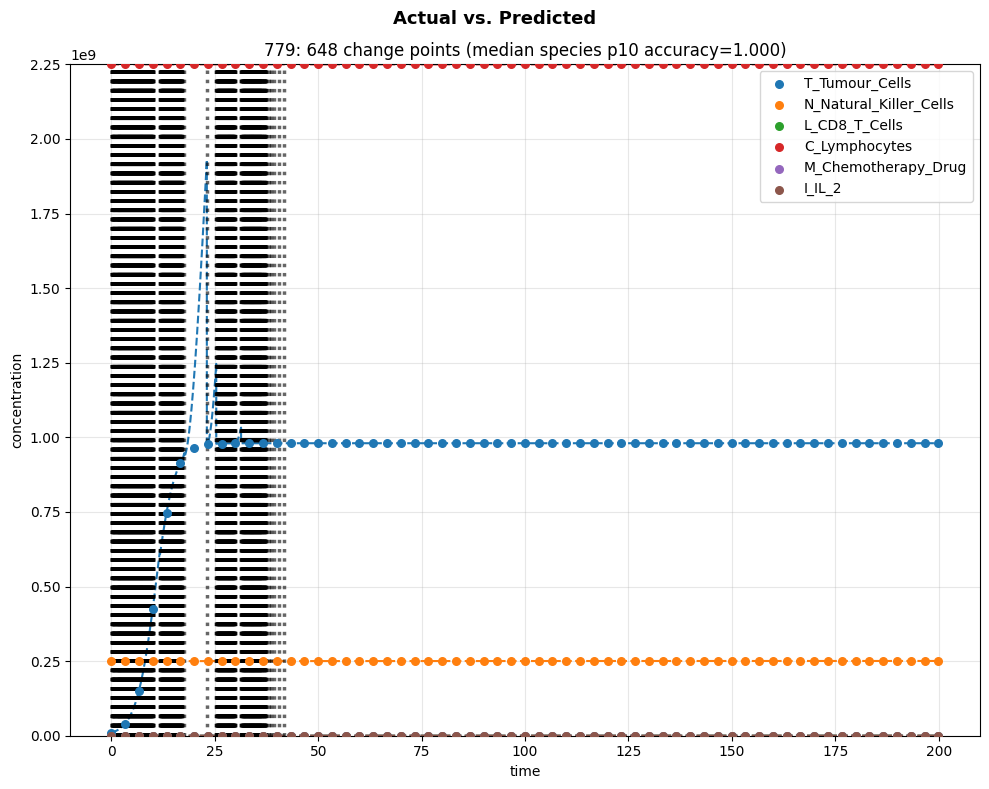

<Figure size 640x480 with 0 Axes>

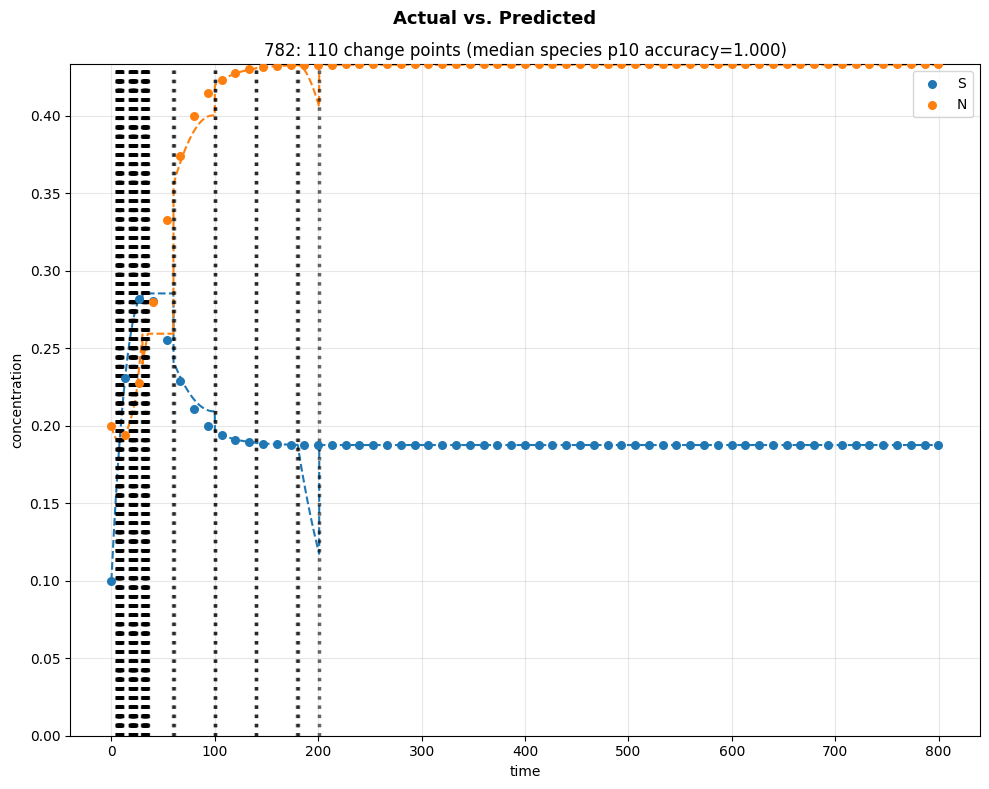

<Figure size 640x480 with 0 Axes>

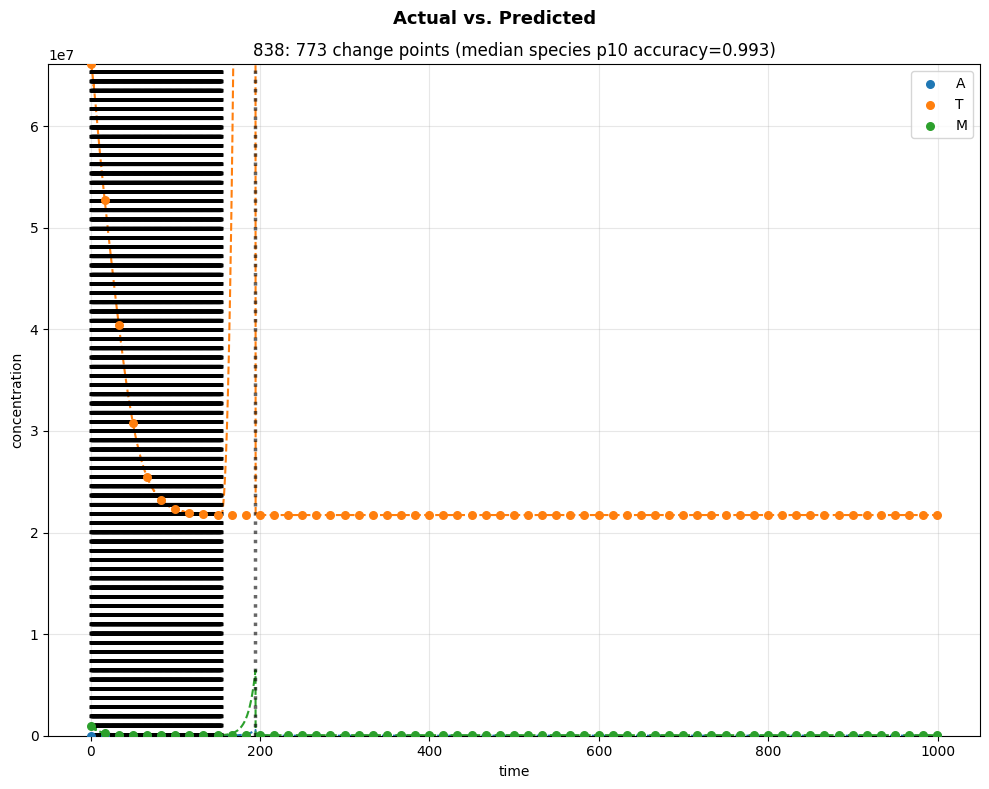

<Figure size 640x480 with 0 Axes>

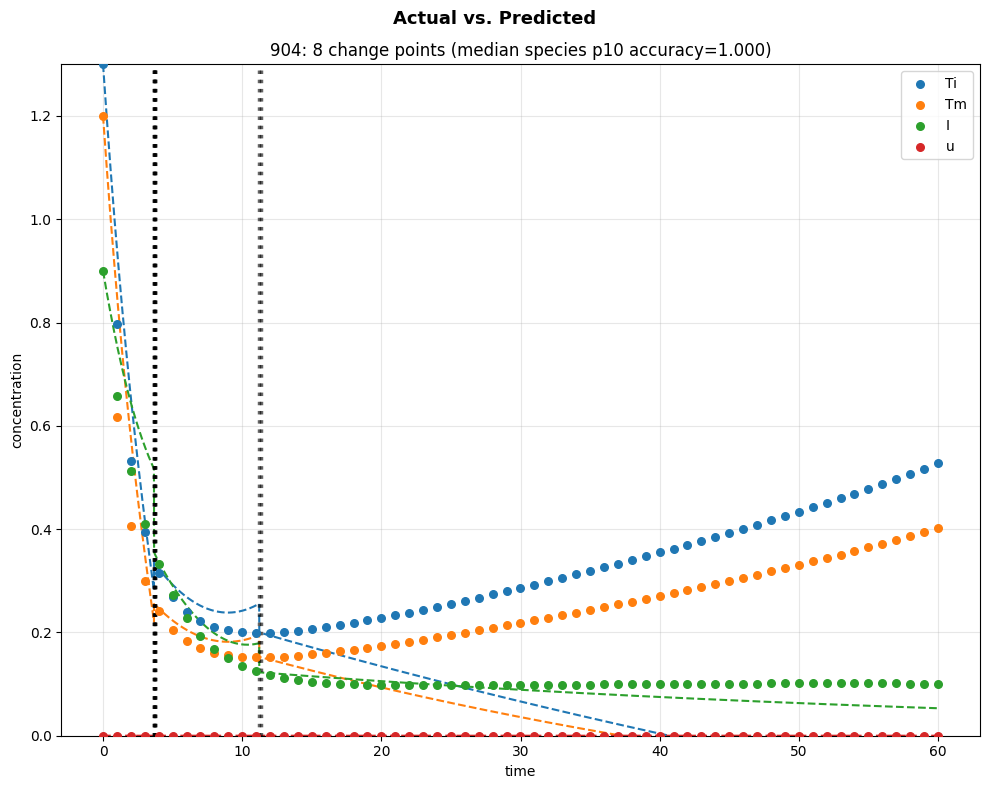

<Figure size 640x480 with 0 Axes>

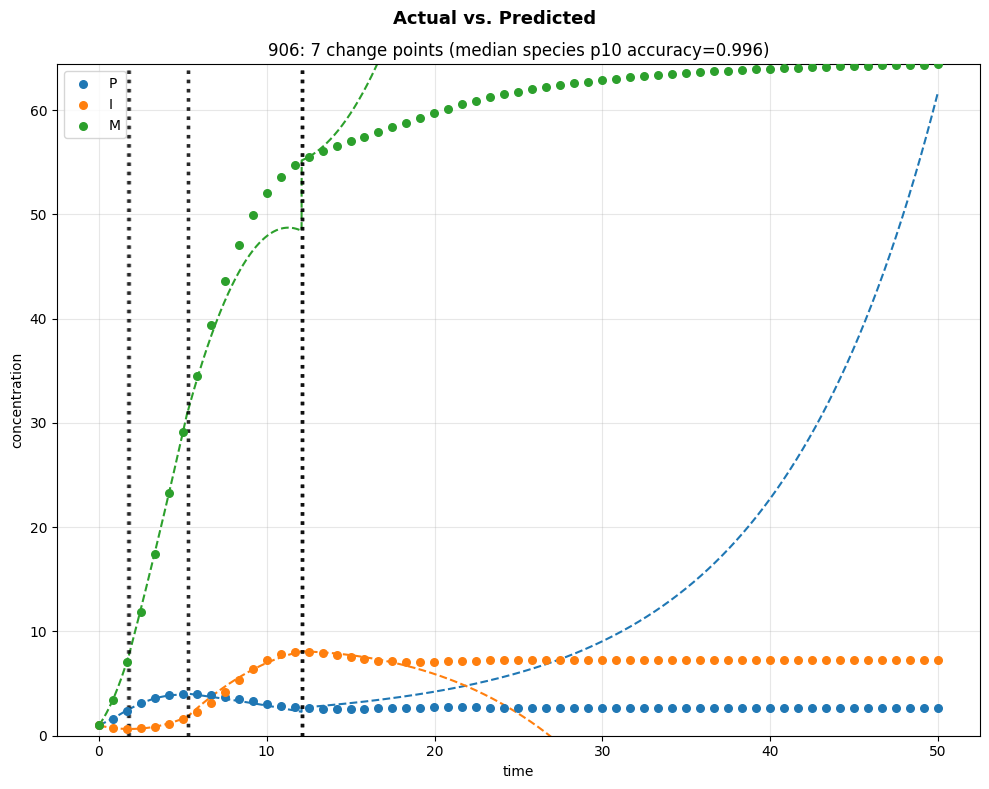

<Figure size 640x480 with 0 Axes>

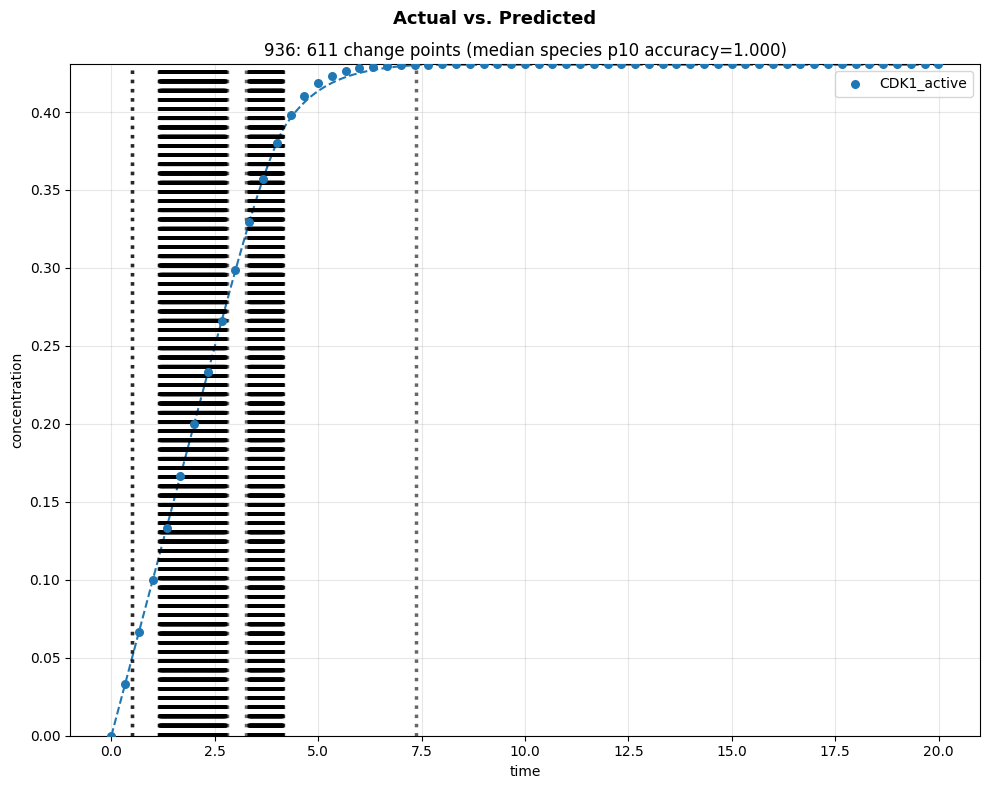

<Figure size 640x480 with 0 Axes>

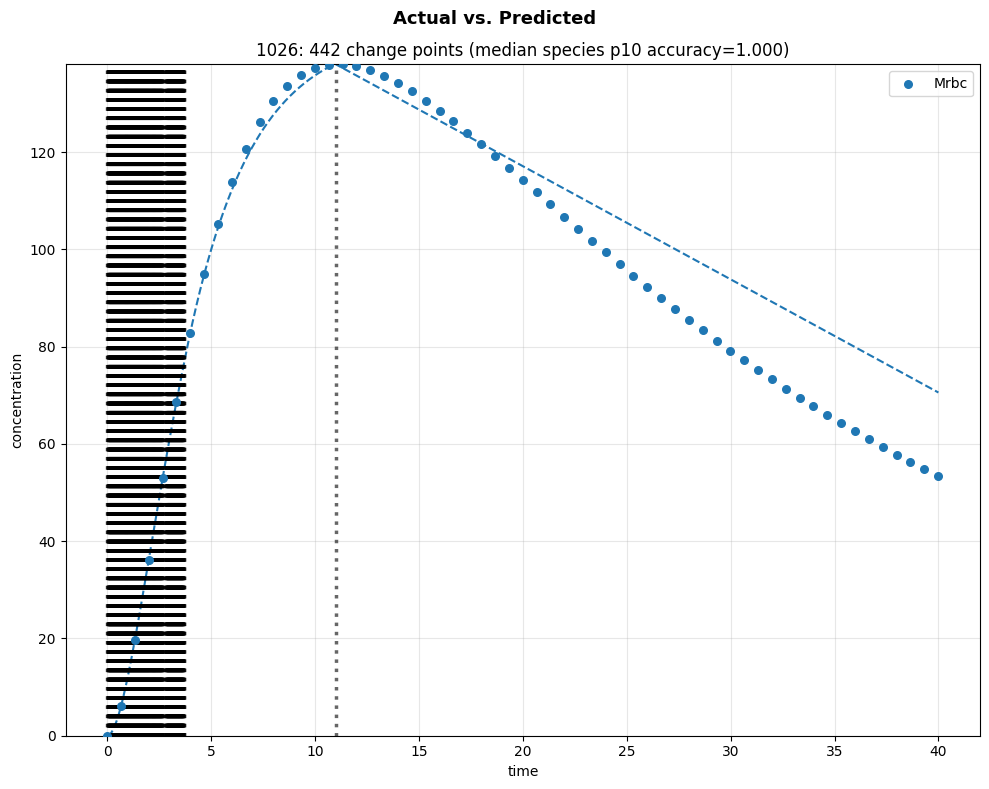

<Figure size 640x480 with 0 Axes>

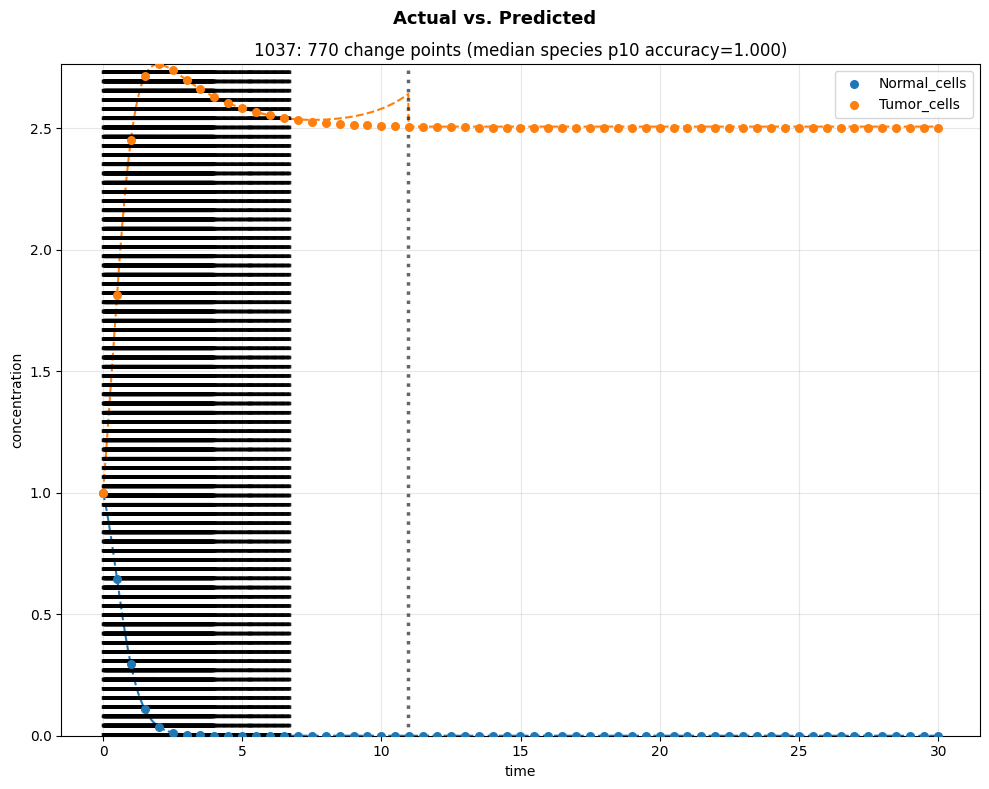

<Figure size 640x480 with 0 Axes>

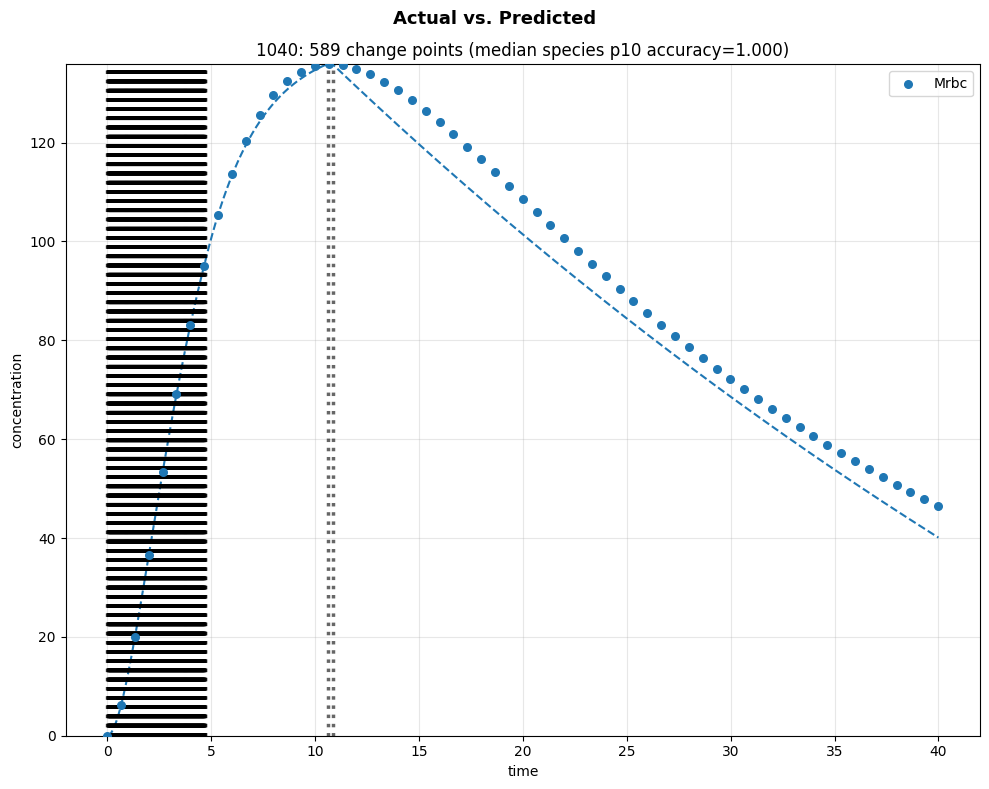

<Figure size 640x480 with 0 Axes>

In [28]:
run(MODEL_COLLECTION)